# 09 · Смесь общих моделей и недельных специалистов

Подбор весов на сохранённых прогнозах за **28 марта — 24 апреля 2016**.
Модели здесь не обучаются. Первая недельная модель уже обновлена до **2076 деревьев**.

| Вариант | WRMSSE |
|---|---:|
| Четыре обновлённых специалиста | 0.494257 |
| Общие веса компонентов | 0.493603 |
| Отдельный вес специалиста по неделям | 0.491385 |
| Смесь × 1.006 | **0.489545** |

Числа относятся к окну подбора. Финальное обучение и конкурсный прогноз — в
[ноутбуке 10](10_final_submission.ipynb).

## 1. Запуск на Kaggle

CPU Notebook. Подключить **M5 Forecasting — Accuracy** и
**`demand-planner_research_forecasts_v1.zip`** из
[GitHub Release](https://github.com/dannya220/demand-planner/releases/tag/v1.0.0).
Подойдёт ZIP или его распакованная папка. В архиве — четыре исходных прогноза,
уже с обновлённой первой неделей. Остальные checkpoint не требуются.

Выводы поиска ниже сохранены из выполненного запуска. Загрузка источников
упрощена после него; её старые выводы убраны. Сами формулы и результаты поиска
весов не изменены. Для пересчёта выполнить ноутбук сверху вниз.

In [1]:
from pathlib import Path
import os
import sys

if not Path("/kaggle/input").is_dir():
    raise RuntimeError("Этот ноутбук предназначен для Kaggle. Локально подбор смеси не запускаем.")
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"

from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZIP_DEFLATED, ZipFile
import gzip
import hashlib
import json
import math
import shutil

import numpy as np
import pandas as pd
import scipy
from IPython.display import FileLink, display

pd.set_option("compute.use_bottleneck", False)
pd.set_option("display.max_columns", 30)
print("NumPy:", np.__version__, "| pandas:", pd.__version__, "| SciPy:", scipy.__version__)
print("Здесь выполняются только чтение прогнозов, WRMSSE и подбор весов.")

NumPy: 2.1.3 | pandas: 2.3.3 | SciPy: 1.16.3
Здесь выполняются только чтение прогнозов, WRMSSE и подбор весов.


## 2. Настройки проверки

Сетка весов — **5%**. Сначала проверяем смеси трёх общих моделей, затем все смеси этих трёх моделей и недельного блока с одним общим весом. Для четырёх компонентов это 1771 комбинация, включая каждый чистый компонент и прежнюю смесь 70 / 30.

Затем допускаем **отдельный вес специалиста на каждую неделю**. Проверяем сетку по одной неделе за шаг, несколько проходов и несколько начальных точек. Общие модели внутри выбранной основы сохраняют одинаковые относительные веса для всех недель. Это ограниченный поиск, а не гарантия глобального оптимума.

Метрика при любом подборе — **полный WRMSSE за 28 дней**. Калибровка отдельной гипотезой выключена по умолчанию: `RUN_CALIBRATION = False`. Если включить её, подбирается один множитель в диапазоне 0.97–1.03, также по WRMSSE.

Если подключено несколько разных первичных прогнозов одного компонента, загрузчик остановится и попросит заполнить `SOURCE_OVERRIDES`. Он не выбирает случайный файл и не усредняет конфликтующие копии.

In [ ]:
HORIZON = 28
SEARCH_ORIGIN = pd.Timestamp("2016-03-27")
RUN_NAME = "ensemble_horizon_week1_3200_v1"
PROJECT_ROOT = Path("/kaggle/working/demand-planner")
RESULT_DIR = PROJECT_ROOT / "results/m5_wrmsse" / RUN_NAME
INPUT_CACHE = PROJECT_ROOT / "forecast_input_cache"
CHECKPOINT_PATH = PROJECT_ROOT.parent / "demand-planner_ensemble_week1_3200_checkpoint.zip"
GRID_UNITS = 20
RUN_WEEK_WEIGHTS = True
MAX_COORDINATE_PASSES = 4
RUN_CALIBRATION = True
CALIBRATION_COEFFICIENTS = np.linspace(0.97, 1.03, 61)
SOURCE_OVERRIDES = {}
EXTRA_CHECKPOINT_ZIPS = []

REQUIRED_FILES = ("calendar.csv", "sales_train_validation.csv", "sell_prices.csv")
candidates = sorted(
    {
        path.parent
        for path in Path("/kaggle/input").rglob("calendar.csv")
        if all((path.parent / name).is_file() for name in REQUIRED_FILES)
    }
)
if len(candidates) != 1:
    raise FileNotFoundError(
        f"Подключи один набор исходных M5 CSV. Найдено папок: {len(candidates)}."
    )
DATA_RAW = candidates[0]
RESULT_DIR.mkdir(parents=True, exist_ok=True)
INPUT_CACHE.mkdir(parents=True, exist_ok=True)
if GRID_UNITS < 1 or MAX_COORDINATE_PASSES < 1:
    raise ValueError("Неверная сетка или число проходов.")

COMPONENTS = [
    {
        "name": "global_trial9_28",
        "label": "Trial 9, 52 × 28",
        "expected_WRMSSE": 0.5019588456962026,
    },
    {
        "name": "global_trial5_28",
        "label": "Trial 5, 52 × 28",
        "expected_WRMSSE": 0.5031034694526212,
    },
    {"name": "global_trial5_8", "label": "Trial 5, 52 × 8", "expected_WRMSSE": 0.5066471330479768},
    {
        "name": "weekly_specialists",
        "label": "Четыре недельные модели",
        "expected_WRMSSE": 0.4942565674509285,
    },
]
for component in COMPONENTS:
    component["hint"] = "Подключи demand-planner_research_forecasts_v1.zip из GitHub Release."
    component["suffixes"] = [
        (
            0,
            f"results/m5_wrmsse/ensemble_horizon_week1_3200_v1/sources/{component['name']}/predictions.csv",
        )
    ]
COMPONENT_NAMES = [component["name"] for component in COMPONENTS]
KNOWN_CHECKPOINT_ZIPS = {"demand-planner_research_forecasts_v1.zip", CHECKPOINT_PATH.name}
print(
    "Историческое окно:",
    (SEARCH_ORIGIN + pd.Timedelta(days=1)).date(),
    "—",
    (SEARCH_ORIGIN + pd.Timedelta(days=HORIZON)).date(),
)
print(
    "Сетка:",
    f"{100 / GRID_UNITS:g}%",
    "| Отдельные веса недель:",
    RUN_WEEK_WEIGHTS,
    "| Калибровка:",
    RUN_CALIBRATION,
)

## 3. История и исходная WRMSSE

Используем ту же реализацию 12 уровней M5, что в ноутбуке 08. Масштабы и денежные веса вычисляются по истории до 27 марта; факты последующих 28 дней служат для исторического подбора весов. Новые признаки и обучающие таблицы не создаются.

In [3]:
calendar = pd.read_csv(DATA_RAW / "calendar.csv", parse_dates=["date"])
if calendar["date"].duplicated().any() or calendar["d"].duplicated().any():
    raise ValueError("В календаре есть повторяющиеся дни.")

In [4]:
identifier_columns = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

series_metadata = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=identifier_columns,
    dtype="string",
)

assert not series_metadata.duplicated(["item_id", "store_id"]).any()
assert len(series_metadata) == 30_490
assert series_metadata["store_id"].nunique() == 10

M5_LEVELS = {
    "Total": [],
    "State": ["state_id"],
    "Store": ["store_id"],
    "Category": ["cat_id"],
    "Department": ["dept_id"],
    "State / Category": ["state_id", "cat_id"],
    "State / Department": ["state_id", "dept_id"],
    "Store / Category": ["store_id", "cat_id"],
    "Store / Department": ["store_id", "dept_id"],
    "Item": ["item_id"],
    "Item / State": ["item_id", "state_id"],
    "Item / Store": ["item_id", "store_id"],
}

hierarchy = pd.DataFrame(
    [
        {
            "level": level,
            "series": (series_metadata.groupby(columns, observed=True).ngroups if columns else 1),
        }
        for level, columns in M5_LEVELS.items()
    ]
).set_index("level")

assert int(hierarchy["series"].sum()) == 42_840
display(hierarchy)
print(f"Всего оцениваемых рядов: {hierarchy['series'].sum():,}")

,series
level,
Total,1
State,3
Store,10
Category,3
Department,7
State / Category,9
State / Department,21
Store / Category,30
Store / Department,70


Всего оцениваемых рядов: 42,840


In [5]:
M5_KEYS = ["store_id", "item_id"]
TRAIN_END_DAY = 1913

train_day_columns = [f"d_{day}" for day in range(1, TRAIN_END_DAY + 1)]

series_index = pd.MultiIndex.from_frame(series_metadata[M5_KEYS])

train_daily = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=[*M5_KEYS, *train_day_columns],
    dtype={
        "store_id": "string",
        "item_id": "string",
        **{column: "int32" for column in train_day_columns},
    },
)

train_daily = train_daily.set_index(M5_KEYS).reindex(series_index).loc[:, train_day_columns]

train_daily.columns = pd.DatetimeIndex(
    calendar.set_index("d").loc[train_day_columns, "date"],
    name="date",
)

weight_dates = train_daily.loc[:, :SEARCH_ORIGIN].columns[-28:]

weight_weeks = calendar.set_index("date").loc[weight_dates, "wm_yr_wk"].unique()

price_parts = []

for chunk in pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    usecols=["store_id", "item_id", "wm_yr_wk", "sell_price"],
    dtype={
        "store_id": "string",
        "item_id": "string",
        "wm_yr_wk": "int32",
        "sell_price": "float64",
    },
    chunksize=200_000,
):
    selected = chunk.loc[chunk["wm_yr_wk"].isin(weight_weeks)]

    if not selected.empty:
        price_parts.append(selected.copy())

prices_for_weights = pd.concat(
    price_parts,
    ignore_index=True,
)

del price_parts

print(f"Рядов: {len(train_daily):,}")
print(f"Дней истории: {train_daily.shape[1]:,}")
print(
    "Период для весов:",
    weight_dates.min().date(),
    "—",
    weight_dates.max().date(),
)

Рядов: 30,490
Дней истории: 1,913
Период для весов: 2016-02-29 — 2016-03-27


In [6]:
from scipy.sparse import csr_matrix


def calculate_rmsse_scale(history_values, aggregation, block_size=128):
    n_groups = aggregation.shape[0]
    n_days = history_values.shape[1]

    first_nonzero = np.full(n_groups, n_days, dtype=np.int32)
    squared_difference_sum = np.zeros(n_groups, dtype=np.float64)
    previous = np.zeros(n_groups, dtype=np.float64)

    for start in range(0, n_days, block_size):
        stop = min(start + block_size, n_days)

        block = np.asarray(
            aggregation @ history_values[:, start:stop],
            dtype=np.float64,
        )

        positive = block > 0
        newly_active = (first_nonzero == n_days) & positive.any(axis=1)

        if newly_active.any():
            first_nonzero[newly_active] = start + positive[newly_active].argmax(axis=1)

        differences = np.empty_like(block)
        differences[:, 0] = block[:, 0] - previous
        differences[:, 1:] = np.diff(block, axis=1)

        positions = np.arange(start, stop)
        exclude = positions[None, :] <= first_nonzero[:, None]
        differences[exclude] = 0.0

        squared_difference_sum += np.einsum(
            "ij,ij->i",
            differences,
            differences,
        )

        previous = block[:, -1].copy()

    difference_count = n_days - first_nonzero - 1

    return np.divide(
        squared_difference_sum,
        difference_count,
        out=np.zeros(n_groups, dtype=np.float64),
        where=difference_count > 0,
    )


class M5WRMSSE:
    def __init__(
        self,
        history,
        metadata,
        calendar,
        prices,
        levels,
        horizon=28,
    ):
        if len(metadata) != 30_490 or len(levels) != 12:
            raise ValueError("Для полного M5 нужны 30 490 рядов и 12 уровней.")

        self.series_index = pd.MultiIndex.from_frame(metadata[M5_KEYS])

        if (
            self.series_index.has_duplicates
            or history.index.has_duplicates
            or len(history) != len(self.series_index)
            or not self.series_index.isin(history.index).all()
        ):
            raise ValueError("Идентификаторы истории и metadata не совпадают.")

        history = history.reindex(self.series_index)

        if history.shape[1] < 28:
            raise ValueError("Для расчёта весов нужны минимум 28 дней.")

        if not isinstance(history.columns, pd.DatetimeIndex):
            raise TypeError("Столбцы истории должны содержать даты.")

        expected_history_dates = pd.date_range(
            history.columns[0],
            periods=history.shape[1],
            freq="D",
        )

        if not history.columns.equals(expected_history_dates):
            raise ValueError("В истории есть пропуски или нарушен порядок дней.")

        history_values = history.to_numpy(copy=False)

        if not np.isfinite(history_values).all() or (history_values < 0).any():
            raise ValueError("История должна содержать конечные неотрицательные продажи.")

        self.horizon = horizon
        self.n_levels = len(levels)
        self.forecast_dates = pd.date_range(
            history.columns[-1] + pd.Timedelta(days=1),
            periods=horizon,
            freq="D",
            name="date",
        )

        recent_dates = history.columns[-28:]

        week_codes = calendar.set_index("date").reindex(recent_dates)["wm_yr_wk"].to_numpy()

        if pd.isna(week_codes).any():
            raise ValueError("В календаре отсутствуют даты для расчёта весов.")

        known_prices = prices["sell_price"].dropna().to_numpy()

        if not np.isfinite(known_prices).all() or (known_prices <= 0).any():
            raise ValueError("Известные цены должны быть конечными и положительными.")

        price_table = prices.pivot(
            index=M5_KEYS,
            columns="wm_yr_wk",
            values="sell_price",
        )

        daily_prices = price_table.reindex(
            index=self.series_index,
            columns=week_codes,
        ).to_numpy(dtype=np.float64)

        recent_units = history.iloc[:, -28:].to_numpy(dtype=np.float64)

        missing_price_with_sales = (recent_units > 0) & ~np.isfinite(daily_prices)

        if missing_price_with_sales.any():
            raise ValueError(
                "Есть положительные продажи без цены: веса нельзя посчитать корректно."
            )

        dollar_sales = (recent_units * np.nan_to_num(daily_prices, nan=0.0)).sum(axis=1)

        total_dollar_sales = dollar_sales.sum()

        if total_dollar_sales <= 0:
            raise ValueError("Суммарные денежные продажи равны нулю.")

        metadata = metadata.reset_index(drop=True)

        self.level_specs = {}
        level_rows = []

        for level_name, columns in levels.items():
            if columns:
                group_index = pd.MultiIndex.from_frame(metadata[columns])
                codes, groups = pd.factorize(
                    group_index,
                    sort=True,
                )
                n_groups = len(groups)
            else:
                codes = np.zeros(len(metadata), dtype=np.int32)
                n_groups = 1

            aggregation = csr_matrix(
                (
                    np.ones(len(metadata), dtype=np.float64),
                    (codes, np.arange(len(metadata))),
                ),
                shape=(n_groups, len(metadata)),
            )

            print(f"Масштабы: {level_name} — {n_groups:,} рядов")

            scale = calculate_rmsse_scale(
                history_values,
                aggregation,
            )

            group_dollar_sales = np.asarray(aggregation @ dollar_sales).ravel()

            weights = group_dollar_sales / total_dollar_sales / self.n_levels

            if ((scale <= 0) & (weights > 0)).any():
                raise ValueError(
                    f"{level_name}: есть ряд с положительным весом " "и нулевым масштабом RMSSE."
                )

            self.level_specs[level_name] = {
                "aggregation": aggregation,
                "scale": scale,
                "weights": weights,
            }

            level_rows.append(
                {
                    "level": level_name,
                    "series": n_groups,
                    "weight_sum": weights.sum(),
                }
            )

        self.level_info = pd.DataFrame(level_rows).set_index("level")

        if self.level_info["series"].sum() != 42_840:
            raise ValueError("Получено неверное число рядов иерархии.")

        if not np.isclose(self.level_info["weight_sum"].sum(), 1.0):
            raise ValueError("Сумма весов WRMSSE отличается от единицы.")

    def _aligned_values(self, frame):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError("Передай DataFrame с идентификаторами и датами.")

        if (
            frame.index.has_duplicates
            or len(frame) != len(self.series_index)
            or not self.series_index.isin(frame.index).all()
        ):
            raise ValueError("Набор товаров и магазинов не совпадает.")

        if not frame.columns.equals(self.forecast_dates):
            raise ValueError("Столбцы должны содержать следующие 28 дат " "в правильном порядке.")

        values = frame.reindex(self.series_index).to_numpy(dtype=np.float64)

        if not np.isfinite(values).all():
            raise ValueError("В фактах или прогнозах есть NaN либо бесконечность.")

        return values

    def score(self, actual, prediction):
        actual_values = self._aligned_values(actual)
        prediction_values = self._aligned_values(prediction)

        bottom_errors = prediction_values - actual_values
        rows = []

        for level_name, spec in self.level_specs.items():
            aggregated_errors = spec["aggregation"] @ bottom_errors

            mse = np.mean(
                np.square(aggregated_errors),
                axis=1,
            )

            rmsse = np.sqrt(
                np.divide(
                    mse,
                    spec["scale"],
                    out=np.zeros_like(mse),
                    where=spec["scale"] > 0,
                )
            )

            contribution = float(np.dot(spec["weights"], rmsse))

            rows.append(
                {
                    "level": level_name,
                    "weighted_RMSSE": contribution * self.n_levels,
                    "contribution": contribution,
                }
            )

        report = pd.DataFrame(rows).set_index("level")
        overall = float(report["contribution"].sum())

        return overall, report

In [7]:
wrmsse_evaluator = M5WRMSSE(
    history=train_daily.loc[:, :SEARCH_ORIGIN],
    metadata=series_metadata,
    calendar=calendar,
    prices=prices_for_weights,
    levels=M5_LEVELS,
    horizon=HORIZON,
)

display(
    wrmsse_evaluator.level_info.style.format(
        {
            "series": "{:,.0f}",
            "weight_sum": "{:.6f}",
        }
    )
)

print(
    "Всего рядов:",
    f"{wrmsse_evaluator.level_info['series'].sum():,}",
)

print(
    "Сумма весов:",
    f"{wrmsse_evaluator.level_info['weight_sum'].sum():.6f}",
)

print(
    "Даты будущего прогноза:",
    wrmsse_evaluator.forecast_dates.min().date(),
    "—",
    wrmsse_evaluator.forecast_dates.max().date(),
)

Масштабы: Total — 1 рядов
Масштабы: State — 3 рядов
Масштабы: Store — 10 рядов
Масштабы: Category — 3 рядов
Масштабы: Department — 7 рядов
Масштабы: State / Category — 9 рядов
Масштабы: State / Department — 21 рядов
Масштабы: Store / Category — 30 рядов
Масштабы: Store / Department — 70 рядов
Масштабы: Item — 3,049 рядов
Масштабы: Item / State — 9,147 рядов
Масштабы: Item / Store — 30,490 рядов


,series,weight_sum
level,,
Total,1,0.083333
State,3,0.083333
Store,10,0.083333
Category,3,0.083333
Department,7,0.083333
State / Category,9,0.083333
State / Department,21,0.083333
Store / Category,30,0.083333
Store / Department,70,0.083333


Всего рядов: 42,840
Сумма весов: 1.000000
Даты будущего прогноза: 2016-03-28 — 2016-04-24


In [8]:
def price_evaluate(evaluator, actual, prediction):
    score, report = evaluator.score(actual, prediction)
    actual_total = (
        actual.reindex(index=prediction.index, columns=prediction.columns)
        .to_numpy(dtype=np.float64)
        .sum()
    )
    metrics = {
        "WRMSSE": float(score),
        "Bias": float(prediction.to_numpy().sum() / actual_total - 1),
    }
    return (metrics, report)

## 4. Загрузка прогнозов

Читаем четыре выровненные таблицы из одного checkpoint. Поддерживаются CSV, gzip
и CSV внутри папки, созданной распаковкой Kaggle. Проверяем 30 490 рядов, 28 дат,
допустимые значения и сохранённый WRMSSE каждого компонента.

In [ ]:
import io


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8"
    )
    temporary.replace(path)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as incoming:
        for block in iter(lambda: incoming.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def read_forecast_payload(path):
    data = Path(path).read_bytes()
    return gzip.decompress(data) if data.startswith(bytes((31, 139))) else data


def payload_hash(path):
    return hashlib.sha256(read_forecast_payload(path)).hexdigest()


def source_priority(path, component):
    path = Path(path)
    candidates = [
        path,
        *[
            parent
            for parent in path.parents
            if parent.name in ("predictions.csv", "predictions.csv.gz")
        ],
    ]
    matches = []
    for candidate in candidates:
        normalized = candidate.as_posix().removesuffix(".gz")
        matches.extend(
            priority
            for priority, suffix in component["suffixes"]
            if normalized.endswith("/" + suffix)
        )
    return min(matches) if matches else None


def import_forecast_zips():
    archives = {
        path
        for path in Path("/kaggle/input").rglob("*.zip")
        if path.is_file() and path.name in KNOWN_CHECKPOINT_ZIPS
    }
    archives.update(Path(path) for path in EXTRA_CHECKPOINT_ZIPS)
    for path in sorted(archives):
        destination = INPUT_CACHE / sha256_file(path)[:16]
        marker = destination / "import_complete.json"
        if marker.is_file():
            continue
        destination.mkdir(parents=True, exist_ok=True)
        count = 0
        with ZipFile(path) as archive:
            selected = []
            for info in archive.infolist():
                if info.is_dir():
                    continue
                relative = Path(info.filename)
                if relative.is_absolute() or ".." in relative.parts:
                    raise ValueError("Некорректный путь в ZIP.")
                if not any(
                    source_priority(Path("/") / relative, component) is not None
                    for component in COMPONENTS
                ):
                    continue
                if (info.external_attr >> 16) & 0o170000 == 0o120000:
                    raise ValueError("Ссылки внутри checkpoint не поддерживаются.")
                selected.append((info, relative))
            for info, relative in selected:
                target = destination / relative
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(info) as incoming, target.open("wb") as outgoing:
                    shutil.copyfileobj(incoming, outgoing)
                count += 1
        atomic_json(marker, {"archive": str(path), "forecast_files_imported": count})
        print(f"{path.name}: извлечено прогнозов {count}.")


def choose_source(component):
    override = SOURCE_OVERRIDES.get(component["name"])
    if override is not None:
        path = Path(override)
        if not path.is_file():
            raise FileNotFoundError(path)
        return path
    candidates = {}
    for root in [Path("/kaggle/input"), INPUT_CACHE]:
        for path in root.rglob("*"):
            if not path.is_file():
                continue
            priority = source_priority(path, component)
            if priority is not None:
                candidates[path] = priority
    if not candidates:
        raise FileNotFoundError(f"Не найден {component['label']}. {component['hint']}")
    priority = min(candidates.values())
    preferred = sorted(path for path, rank in candidates.items() if rank == priority)
    hashes = {payload_hash(path) for path in preferred}
    if len(hashes) > 1:
        listing = "\n".join(map(str, preferred))
        raise ValueError(
            f"Разные первичные копии {component['name']}. Укажи одну в SOURCE_OVERRIDES:\n{listing}"
        )
    return preferred[0]


def read_prediction(path):
    frame = pd.read_csv(
        io.BytesIO(read_forecast_payload(path)),
        index_col=M5_KEYS,
        dtype={key: "string" for key in M5_KEYS},
        float_precision="round_trip",
    )
    frame.columns = pd.DatetimeIndex(pd.to_datetime(frame.columns), name="date")
    canonical = wrmsse_evaluator.series_index
    if (
        frame.index.has_duplicates
        or len(frame) != len(canonical)
        or not canonical.isin(frame.index).all()
        or not frame.columns.equals(wrmsse_evaluator.forecast_dates)
    ):
        raise ValueError(f"Неверные идентификаторы или даты: {path}")
    frame = frame.reindex(canonical)
    values = frame.to_numpy(dtype=np.float64)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError(f"Некорректные значения прогноза: {path}")
    return frame


def export_ensemble_checkpoint():
    temporary = CHECKPOINT_PATH.with_suffix(".tmp.zip")
    with ZipFile(temporary, "w", ZIP_DEFLATED, compresslevel=1) as archive:
        for path in sorted(RESULT_DIR.rglob("*")):
            if path.is_file() and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(PROJECT_ROOT))
    temporary.replace(CHECKPOINT_PATH)
    print("Checkpoint:", CHECKPOINT_PATH.name)

In [ ]:
import_forecast_zips()
actual = train_daily.loc[wrmsse_evaluator.series_index, wrmsse_evaluator.forecast_dates]
frames = {}
component_rows = []
provenance = []
for component in COMPONENTS:
    source_path = choose_source(component)
    frame = read_prediction(source_path)
    metrics, levels = price_evaluate(wrmsse_evaluator, actual, frame)
    if not np.isclose(metrics["WRMSSE"], component["expected_WRMSSE"], rtol=1e-9, atol=1e-9):
        raise RuntimeError(
            f"{component['label']}: WRMSSE {metrics['WRMSSE']:.9f} не совпал с сохранённым {component['expected_WRMSSE']:.9f}."
        )
    frames[component["name"]] = frame
    directory = RESULT_DIR / "sources" / component["name"]
    directory.mkdir(parents=True, exist_ok=True)
    frame.to_csv(directory / "predictions.csv.gz", compression="gzip")
    levels.to_csv(directory / "metrics_by_level.csv")
    component_rows.append({"model": component["label"], **metrics})
    provenance.append(
        {
            "name": component["name"],
            "source": str(source_path),
            "source_payload_sha256": payload_hash(source_path),
            "saved_payload_sha256": payload_hash(directory / "predictions.csv.gz"),
            "metrics": metrics,
        }
    )
    print(f"Загружен {component['label']}: WRMSSE {metrics['WRMSSE']:.6f}", flush=True)
atomic_json(RESULT_DIR / "input_provenance.json", provenance)
atomic_json(
    RESULT_DIR / "evaluation_protocol.json",
    {
        "origin": str(SEARCH_ORIGIN.date()),
        "horizon": HORIZON,
        "levels": list(M5_LEVELS),
        "raw_sha256": {name: sha256_file(DATA_RAW / name) for name in REQUIRED_FILES},
        "grid_units": GRID_UNITS,
        "coordinate_passes": MAX_COORDINATE_PASSES,
        "historical_development_score": True,
        "model_training_or_inference": False,
    },
)
display(
    pd.DataFrame(component_rows)
    .set_index("model")
    .style.format({"WRMSSE": "{:.6f}", "Bias": "{:+.2%}"})
)
export_ensemble_checkpoint()

## 5. Быстрый расчёт смеси

Ошибки каждого компонента агрегируются на 12 уровнях один раз. Для общих весов храним попарные произведения ошибок; для отдельных недель — суммы квадратов и перекрёстных произведений внутри каждого семидневного блока.

Это алгебраическое ускорение той же WRMSSE. Проверяем совпадение с исходным evaluator для чистых компонентов, прежней смеси и нескольких пробных весов. Лучшие результаты также пересчитываются исходной функцией.

In [13]:
def simplex_grid(parts, units):
    if parts == 1:
        yield (units,)
    else:
        for first in range(units + 1):
            for tail in simplex_grid(parts - 1, units - first):
                yield (first, *tail)


def weight_vector(values, length):
    values = np.asarray(values, dtype=np.float64)
    if values.shape != (length,) or not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Некорректные веса.")
    if not np.isclose(values.sum(), 1, rtol=0, atol=1e-12):
        raise ValueError("Сумма весов должна быть равна единице.")
    return values


def score_from_mse(mse, factors):
    if not np.isfinite(mse).all():
        raise ValueError("Неконечная ошибка смеси.")
    return float(np.dot(factors, np.sqrt(np.maximum(mse, 0.0))))


def constant_weight_metric(gram, factors):
    def score(weights):
        weights = weight_vector(weights, gram.shape[0])
        mse = np.einsum("i,j,ijg->g", weights, weights, gram, optimize=True)
        return score_from_mse(mse, factors)

    return score


def weekly_weight_metric(base_errors, specialist_errors, factors):
    if base_errors.shape != specialist_errors.shape or base_errors.shape[1] != 28:
        raise ValueError("Ожидаются агрегированные ошибки всех 28 дней.")
    base_square, cross, delta_square = [], [], []
    for start in range(0, 28, 7):
        base = base_errors[:, start : start + 7]
        delta = specialist_errors[:, start : start + 7] - base
        base_square.append(np.einsum("gt,gt->g", base, base))
        cross.append(np.einsum("gt,gt->g", base, delta))
        delta_square.append(np.einsum("gt,gt->g", delta, delta))
    base_square, cross, delta_square = map(np.asarray, (base_square, cross, delta_square))

    def score(alphas):
        alphas = np.asarray(alphas, dtype=np.float64)
        if (
            alphas.shape != (4,)
            or not np.isfinite(alphas).all()
            or ((alphas < 0) | (alphas > 1)).any()
        ):
            raise ValueError("Ожидаются четыре веса специалистов от 0 до 1.")
        column = alphas[:, None]
        mse = np.sum(base_square + 2 * column * cross + column**2 * delta_square, axis=0) / 28
        return score_from_mse(mse, factors)

    return score


def compose_weekly(values, global_weights, alphas):
    global_weights = weight_vector(global_weights, 3)
    alphas = np.asarray(alphas, dtype=np.float64)
    if alphas.shape != (4,) or not np.isfinite(alphas).all() or ((alphas < 0) | (alphas > 1)).any():
        raise ValueError("Некорректные недельные веса.")
    base = np.einsum("i,ist->st", global_weights, values[:3], optimize=True)
    result = base.copy()
    for week, alpha in enumerate(alphas):
        columns = slice(week * 7, (week + 1) * 7)
        result[:, columns] = (1 - alpha) * base[:, columns] + alpha * values[3, :, columns]
    return result


def coordinate_search(metric, starts, grid, max_passes):
    best = None
    records = []
    for start_number, start in enumerate(starts):
        alphas = np.asarray(start, dtype=np.float64).copy()
        current = metric(alphas)
        records.append(
            {
                "start": start_number,
                "pass": -1,
                "coordinate": -1,
                "WRMSSE": current,
                **{f"alpha_week_{k+1}": float(value) for k, value in enumerate(alphas)},
            }
        )
        for pass_number in range(max_passes):
            improved = False
            for week in range(4):
                selected = alphas.copy()
                selected_score = current
                for value in grid:
                    candidate = alphas.copy()
                    candidate[week] = value
                    score = metric(candidate)
                    records.append(
                        {
                            "start": start_number,
                            "pass": pass_number,
                            "coordinate": week + 1,
                            "WRMSSE": score,
                            **{f"alpha_week_{k+1}": float(v) for k, v in enumerate(candidate)},
                        }
                    )
                    if score < selected_score - 1e-12:
                        selected, selected_score = candidate, score
                if selected_score < current - 1e-12:
                    alphas, current, improved = selected, selected_score, True
            if not improved:
                break
        if best is None or current < best["WRMSSE"] - 1e-12:
            best = {"alphas": alphas.copy(), "WRMSSE": current}
    return best, records

In [15]:
values = np.stack([frames[name].to_numpy(dtype=np.float64) for name in COMPONENT_NAMES])
actual_values = actual.to_numpy(dtype=np.float64)
aggregation = scipy.sparse.vstack(
    [spec["aggregation"] for spec in wrmsse_evaluator.level_specs.values()], format="csr"
)
scales = np.concatenate([spec["scale"] for spec in wrmsse_evaluator.level_specs.values()])
metric_weights = np.concatenate([spec["weights"] for spec in wrmsse_evaluator.level_specs.values()])
factors = np.divide(
    metric_weights, np.sqrt(scales), out=np.zeros_like(metric_weights), where=scales > 0
)
aggregated_errors = np.stack([aggregation @ (prediction - actual_values) for prediction in values])
gram = np.einsum("igt,jgt->ijg", aggregated_errors, aggregated_errors, optimize=True) / HORIZON
full_score = constant_weight_metric(gram, factors)


def frame_from_values(prediction):
    return pd.DataFrame(
        prediction, index=wrmsse_evaluator.series_index, columns=wrmsse_evaluator.forecast_dates
    )


def check_full_score(prediction, expected):
    metrics, levels = price_evaluate(wrmsse_evaluator, actual, frame_from_values(prediction))
    if not np.isclose(metrics["WRMSSE"], expected, rtol=1e-10, atol=1e-10):
        raise RuntimeError(
            f"Ускоренная WRMSSE {expected:.12f} не совпала с полной {metrics['WRMSSE']:.12f}."
        )
    return metrics, levels


for i, component in enumerate(COMPONENTS):
    unit = np.eye(4)[i]
    check_full_score(values[i], full_score(unit))
old_weights = np.array([0.7, 0.0, 0.3, 0.0])
old_prediction = np.einsum("i,ist->st", old_weights, values, optimize=True)
old_metrics, _ = check_full_score(old_prediction, full_score(old_weights))
if not np.isclose(old_metrics["WRMSSE"], 0.500879332781371, rtol=1e-9, atol=1e-9):
    raise RuntimeError("Прежняя смесь 70 / 30 не воспроизвелась.")
probe = np.array([0.25, 0.25, 0.25, 0.25])
check_full_score(np.einsum("i,ist->st", probe, values, optimize=True), full_score(probe))
probe_global = np.array([0.7, 0.0, 0.3])
base_errors = np.einsum("i,igt->gt", probe_global, aggregated_errors[:3], optimize=True)
probe_metric = weekly_weight_metric(base_errors, aggregated_errors[3], factors)
for alphas in [np.zeros(4), np.ones(4), np.array([0.2, 0.4, 0.6, 0.8])]:
    check_full_score(compose_weekly(values, probe_global, alphas), probe_metric(alphas))
print("Проверки полной и ускоренной WRMSSE прошли. Прежняя смесь:", f"{old_metrics['WRMSSE']:.6f}")

Проверки полной и ускоренной WRMSSE прошли. Прежняя смесь: 0.500879


## 6. Постоянные веса

Перебираем сетку 5% для трёх общих моделей, затем добавляем недельный блок.
Четыре компонента дают 1771 комбинацию, включая чистые прогнозы и прежнюю смесь 70 / 30.

In [16]:
started = perf_counter()
global_rows = []
for units in simplex_grid(3, GRID_UNITS):
    weights = np.array([*units, 0], dtype=np.float64) / GRID_UNITS
    global_rows.append(
        {"WRMSSE": full_score(weights), **dict(zip(COMPONENT_NAMES, map(float, weights)))}
    )
global_table = pd.DataFrame(global_rows).sort_values("WRMSSE", kind="stable").reset_index(drop=True)
global_table.to_csv(RESULT_DIR / "global_only_weight_search.csv", index=False)
best_global = global_table.iloc[0][COMPONENT_NAMES[:3]].to_numpy(dtype=float)

constant_rows = []
for number, units in enumerate(simplex_grid(4, GRID_UNITS), start=1):
    weights = np.asarray(units, dtype=np.float64) / GRID_UNITS
    constant_rows.append(
        {"WRMSSE": full_score(weights), **dict(zip(COMPONENT_NAMES, map(float, weights)))}
    )
    if number % 500 == 0:
        print(f"Проверено смесей: {number}", flush=True)
constant_table = (
    pd.DataFrame(constant_rows).sort_values("WRMSSE", kind="stable").reset_index(drop=True)
)
constant_table.to_csv(RESULT_DIR / "constant_weight_search.csv", index=False)
best_constant = constant_table.iloc[0][COMPONENT_NAMES].to_numpy(dtype=float)
constant_prediction = np.einsum("i,ist->st", best_constant, values, optimize=True)
constant_metrics, _ = check_full_score(constant_prediction, full_score(best_constant))
print("Лучшие постоянные веса:", dict(zip(COMPONENT_NAMES, best_constant)))
print(
    "WRMSSE:",
    f"{constant_metrics['WRMSSE']:.6f}",
    "| Подбор, секунд:",
    f"{perf_counter() - started:.1f}",
)
display(
    constant_table.head(10).style.format(
        {"WRMSSE": "{:.6f}", **{name: "{:.0%}" for name in COMPONENT_NAMES}}
    )
)
export_ensemble_checkpoint()

Проверено смесей: 500
Проверено смесей: 1000
Проверено смесей: 1500
Лучшие постоянные веса: {'global_trial9_28': np.float64(0.05), 'global_trial5_28': np.float64(0.0), 'global_trial5_8': np.float64(0.15), 'weekly_specialists': np.float64(0.8)}
WRMSSE: 0.493603 | Подбор, секунд: 1.2


,WRMSSE,global_trial9_28,global_trial5_28,global_trial5_8,weekly_specialists
0,0.493603,5%,0%,15%,80%
1,0.493615,10%,0%,15%,75%
2,0.493619,10%,0%,10%,80%
3,0.493644,15%,0%,10%,75%
4,0.493647,0%,0%,20%,80%
5,0.493648,5%,0%,20%,75%
6,0.493652,0%,0%,15%,85%
7,0.493656,5%,0%,10%,85%
8,0.493687,5%,5%,10%,80%
9,0.493690,15%,0%,15%,70%


Checkpoint: demand-planner_ensemble_week1_3200_checkpoint.zip


## 7. Отдельный вес специалиста каждой недели

Для недели k используем `(1 − alpha_k) × общая смесь + alpha_k × специалист недели k`. Нулевой вес оставляет общую смесь, единичный — только специалиста. Общая основа выбирается из лучшей смеси трёх общих моделей и общей части лучшей постоянной смеси.

Все четыре alpha подбираются по полному WRMSSE за 28 дней, а не по среднему недельных ошибок. Параметров смеси стало больше; оценка остаётся на окне разработки.

In [17]:
selected_values = constant_prediction
selected_fast_score = full_score(best_constant)
selected_description = {
    "kind": "constant_weights",
    "weights": dict(zip(COMPONENT_NAMES, map(float, best_constant))),
}
weekly_records = []
if RUN_WEEK_WEIGHTS:
    bases = {"best_global_only": best_global}
    global_mass = best_constant[:3].sum()
    if global_mass > 1e-12:
        proposed = best_constant[:3] / global_mass
        if not np.allclose(proposed, best_global, rtol=0, atol=1e-12):
            bases["global_part_of_best_constant"] = proposed
    for base_name, base_weights in bases.items():
        base_errors = np.einsum("i,igt->gt", base_weights, aggregated_errors[:3], optimize=True)
        metric = weekly_weight_metric(base_errors, aggregated_errors[3], factors)
        common_scores = [
            (metric(np.full(4, alpha)), alpha) for alpha in np.linspace(0, 1, GRID_UNITS + 1)
        ]
        common_alpha = min(common_scores)[1]
        starts = [np.zeros(4), np.ones(4), np.full(4, common_alpha)]
        winner, records = coordinate_search(
            metric, starts, np.linspace(0, 1, GRID_UNITS + 1), MAX_COORDINATE_PASSES
        )
        weekly_records.extend({"base": base_name, **record} for record in records)
        prediction = compose_weekly(values, base_weights, winner["alphas"])
        metrics, _ = check_full_score(prediction, winner["WRMSSE"])
        print(base_name, "alpha:", winner["alphas"], "WRMSSE:", f"{metrics['WRMSSE']:.6f}")
        if winner["WRMSSE"] < selected_fast_score - 1e-12:
            selected_values = prediction
            selected_fast_score = winner["WRMSSE"]
            selected_description = {
                "kind": "weekly_specialist_weights",
                "global_weights": dict(zip(COMPONENT_NAMES[:3], map(float, base_weights))),
                "specialist_weights_by_week": list(map(float, winner["alphas"])),
            }
    pd.DataFrame(weekly_records).to_csv(RESULT_DIR / "weekly_weight_search.csv", index=False)
selected_metrics, selected_levels = check_full_score(selected_values, selected_fast_score)
atomic_json(
    RESULT_DIR / "best_weights.json",
    {**selected_description, "metrics": selected_metrics, "historical_development_score": True},
)
print("Выбранный вариант:", selected_description)
print("WRMSSE до калибровки:", f"{selected_metrics['WRMSSE']:.6f}")
export_ensemble_checkpoint()

best_global_only alpha: [0.45 1.   0.45 1.  ] WRMSSE: 0.492187
global_part_of_best_constant alpha: [0.4 1.  0.5 1. ] WRMSSE: 0.491385
Выбранный вариант: {'kind': 'weekly_specialist_weights', 'global_weights': {'global_trial9_28': 0.25, 'global_trial5_28': 0.0, 'global_trial5_8': 0.7499999999999999}, 'specialist_weights_by_week': [0.4, 1.0, 0.5, 1.0]}
WRMSSE до калибровки: 0.491385
Checkpoint: demand-planner_ensemble_week1_3200_checkpoint.zip


## 8. Калибровка

Проверяем множитель **0.97–1.03** с шагом **0.001**. Цель — минимальный WRMSSE.
Выбран **1.006**. Коэффициент применяется ко всему прогнозу один раз;
точное зануление Bias не является целью.

In [18]:
calibration_coefficient = 1.0
final_values = selected_values
final_metrics, final_levels = selected_metrics, selected_levels
if RUN_CALIBRATION:
    aggregated_prediction = aggregation @ selected_values
    aggregated_actual = aggregation @ actual_values
    p2 = np.mean(aggregated_prediction**2, axis=1)
    py = np.mean(aggregated_prediction * aggregated_actual, axis=1)
    y2 = np.mean(aggregated_actual**2, axis=1)
    calibration_rows = []
    for coefficient in sorted({1.0, *map(float, CALIBRATION_COEFFICIENTS)}):
        score = score_from_mse(coefficient**2 * p2 - 2 * coefficient * py + y2, factors)
        calibration_rows.append({"coefficient": coefficient, "WRMSSE": score})
    calibration_table = pd.DataFrame(calibration_rows).sort_values("WRMSSE", kind="stable")
    calibration_table.to_csv(RESULT_DIR / "calibration_search.csv", index=False)
    candidate = float(calibration_table.iloc[0]["coefficient"])
    if float(calibration_table.iloc[0]["WRMSSE"]) < selected_metrics["WRMSSE"] - 1e-12:
        calibration_coefficient = candidate
        final_values = candidate * selected_values
        final_metrics, final_levels = check_full_score(
            final_values, float(calibration_table.iloc[0]["WRMSSE"])
        )
    print("Коэффициент:", calibration_coefficient, "| WRMSSE:", f"{final_metrics['WRMSSE']:.6f}")
else:
    print("Калибровка выключена. Сохраняем смесь без изменения масштаба.")

Коэффициент: 1.006 | WRMSSE: 0.489545


## 9. Сохранение результата

Итог: **WRMSSE 0.489545**, Bias **+0.21%**. Недельные веса специалиста:
**0.4, 1.0, 0.5, 1.0**. Общая основа — **25% trial 9 на 28 + 75% trial 5 на 8**.

Checkpoint содержит четыре исходных прогноза, выбранные веса, калибровку и итог.
Зафиксированный рецепт перенесён в [ноутбук 10](10_final_submission.ipynb).

In [19]:
directory = RESULT_DIR / "best_blend"
directory.mkdir(parents=True, exist_ok=True)
frame_from_values(final_values).to_csv(directory / "predictions.csv.gz", compression="gzip")
final_levels.to_csv(directory / "metrics_by_level.csv")
atomic_json(
    directory / "protocol.json",
    {
        "origin": str(SEARCH_ORIGIN.date()),
        "horizon": HORIZON,
        "metrics": final_metrics,
        "weights": selected_description,
        "calibration_coefficient": calibration_coefficient,
        "source_components": COMPONENT_NAMES,
        "historical_development_score": True,
    },
)
summary = pd.DataFrame(
    [
        {"model": "Прежняя смесь 70 / 30", **old_metrics},
        {
            "model": "Четыре недельные модели",
            **{key: component_rows[3][key] for key in ("WRMSSE", "Bias")},
        },
        {"model": "Лучшая постоянная смесь", **constant_metrics},
        {"model": "Выбранная смесь без калибровки", **selected_metrics},
        {"model": "Итог", **final_metrics},
    ]
)
summary = summary.set_index("model")
summary["gain_vs_old_blend"] = 1 - summary["WRMSSE"] / old_metrics["WRMSSE"]
summary["gain_vs_specialists"] = 1 - summary["WRMSSE"] / component_rows[3]["WRMSSE"]
summary.to_csv(RESULT_DIR / "comparison.csv")
display(
    summary.style.format(
        {
            "WRMSSE": "{:.6f}",
            "Bias": "{:+.2%}",
            "gain_vs_old_blend": "{:+.2%}",
            "gain_vs_specialists": "{:+.2%}",
        }
    )
)
print("Все оценки — на историческом окне подбора. Официального Kaggle score здесь нет.")
export_ensemble_checkpoint()
display(FileLink(os.path.relpath(CHECKPOINT_PATH, Path.cwd())))

,WRMSSE,Bias,gain_vs_old_blend,gain_vs_specialists
model,,,,
Прежняя смесь 70 / 30,0.500879,-0.52%,+0.00%,-1.34%
Четыре недельные модели,0.494257,-0.47%,+1.32%,+0.00%
Лучшая постоянная смесь,0.493603,-0.55%,+1.45%,+0.13%
Выбранная смесь без калибровки,0.491385,-0.39%,+1.90%,+0.58%
Итог,0.489545,+0.21%,+2.26%,+0.95%


Все оценки — на историческом окне подбора. Официального Kaggle score здесь нет.
Checkpoint: demand-planner_ensemble_week1_3200_checkpoint.zip


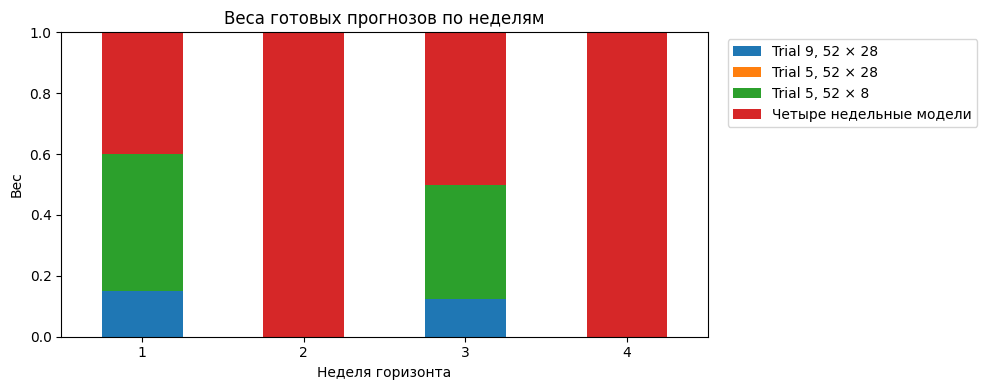

Checkpoint: demand-planner_ensemble_week1_3200_checkpoint.zip


In [20]:
if selected_description["kind"] == "constant_weights":
    week_weights = np.tile(
        [selected_description["weights"][name] for name in COMPONENT_NAMES], (4, 1)
    )
else:
    base_weights = np.array(
        [selected_description["global_weights"][name] for name in COMPONENT_NAMES[:3]]
    )
    alphas = np.array(selected_description["specialist_weights_by_week"])
    week_weights = np.column_stack([(1 - alphas[:, None]) * base_weights, alphas])
weights_table = pd.DataFrame(
    week_weights, columns=COMPONENT_NAMES, index=pd.Index(range(1, 5), name="forecast_week")
)
weights_table.to_csv(RESULT_DIR / "weights_by_week.csv")
import matplotlib.pyplot as plt

ax = weights_table.rename(
    columns={component["name"]: component["label"] for component in COMPONENTS}
).plot.bar(stacked=True, figsize=(10, 4), ylim=(0, 1), rot=0)
ax.set(xlabel="Неделя горизонта", ylabel="Вес", title="Веса готовых прогнозов по неделям")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULT_DIR / "weights_by_week.png", dpi=150)
plt.show()
plt.close(fig)
export_ensemble_checkpoint()

### Документация

- [Kaggle: подключение Output и сохранённых данных](https://www.kaggle.com/docs/notebooks)
- [NumPy: einsum](https://numpy.org/doc/stable/reference/generated/numpy.einsum.html)
- [SciPy: разреженные матрицы](https://docs.scipy.org/doc/scipy/reference/sparse.html)